# A/B Test Analysis: Marketing Campaign (ad vs. PSA)

**Question:** did showing the advertisement (`ad`) increase the conversion rate compared with showing a public service announcement (`psa`), and was the experiment large enough to tell?

## Design
- **Treatment (`ad`):** the user sees the advertisement.
- **Control (`psa`):** the user sees a public service announcement.
- **Outcome:** `converted` (1 = converted, 0 = did not).

## Method
Data checks first, then a two-proportion z-test with confidence intervals, a power analysis, and an exploratory look at segments (day and hour) with multiple-testing correction.

> **Data note:** public Kaggle dataset (CC0). The author does not document how the data was collected or generated, so the results are a **methodological exercise**, not evidence about a real campaign.

## 1. Setup and load

In [25]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import (
    proportions_ztest, confint_proportions_2indep, proportion_confint, proportion_effectsize,
)
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests

DATA_PATH = "../data/raw/marketing_AB.csv"   
OUT_DIR = "../data/processed"
PLANNED_SHARE_AD = None  

DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ALPHA = 0.05

In [26]:
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df = df.drop(columns=[c for c in df.columns if c.startswith("unnamed")])

expected = {"user_id", "test_group", "converted", "total_ads", "most_ads_day", "most_ads_hour"}
missing = expected - set(df.columns)
assert not missing, f"Missing columns: {missing}. Found: {list(df.columns)}"

print(f"Rows: {len(df):,} | Columns: {list(df.columns)}")
df.head()

Rows: 588,101 | Columns: ['user_id', 'test_group', 'converted', 'total_ads', 'most_ads_day', 'most_ads_hour']


,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


## 2. Data quality checks

In [27]:
# `converted` may be read as bool or text; make it 0/1
df["converted"] = df["converted"].astype(str).str.strip().str.lower().map({"true": 1, "false": 0, "1": 1, "0": 0})
assert df["converted"].notna().all(), "converted has values other than True/False/1/0"
df["converted"] = df["converted"].astype(int)

users_in_both = int((df.groupby("user_id")["test_group"].nunique() > 1).sum())
checks = pd.Series({
    "Missing values (expected columns)": int(df[list(expected)].isna().sum().sum()),
    "Fully duplicated rows": int(df.duplicated().sum()),
    "Duplicated user_id": int(df["user_id"].duplicated().sum()),
    "Users present in both groups": users_in_both,
    "Groups found": ", ".join(sorted(df["test_group"].astype(str).unique())),
    "total_ads < 0": int((df["total_ads"] < 0).sum()),
    "most_ads_hour outside 0-23": int((~df["most_ads_hour"].between(0, 23)).sum()),
    "most_ads_day not a weekday name": int((~df["most_ads_day"].isin(DAYS)).sum()),
})
display(checks.to_frame("result"))

# Hard stops: problems that would invalidate the experiment
assert set(df["test_group"].unique()) == {"ad", "psa"}, "Unexpected group labels"
assert checks["Missing values (expected columns)"] == 0, "Missing values found"
assert users_in_both == 0, "Some users appear in both groups"
print("Critical checks passed.")

,result
Missing values (expected columns),0
Fully duplicated rows,0
Duplicated user_id,0
Users present in both groups,0
Groups found,"ad, psa"
total_ads < 0,0
most_ads_hour outside 0-23,0
most_ads_day not a weekday name,0


Critical checks passed.


## 3. Experiment checks
Group sizes and split. The planned split is not documented for this dataset, so the sample-ratio check below only runs if you set `PLANNED_SHARE_AD`.

In [28]:
sizes = df["test_group"].value_counts()
n_ad, n_psa = int(sizes["ad"]), int(sizes["psa"])
share_ad = n_ad / (n_ad + n_psa)
print(f"ad: {n_ad:,} ({share_ad:.1%}) | psa: {n_psa:,} ({1 - share_ad:.1%}) | ratio ad/psa = {n_ad / n_psa:.1f}")

if PLANNED_SHARE_AD is not None:
    N = n_ad + n_psa
    z_srm = (n_ad - N * PLANNED_SHARE_AD) / math.sqrt(N * PLANNED_SHARE_AD * (1 - PLANNED_SHARE_AD))
    p_srm = math.erfc(abs(z_srm) / math.sqrt(2))
    print(f"Sample-ratio check vs planned {PLANNED_SHARE_AD:.0%}: z = {z_srm:.2f}, p = {p_srm:.4f}")
    print("A very small p-value signals a problem in how users were assigned.")
else:
    print("Planned split unknown: sample-ratio check skipped. A highly unbalanced split reduces the power for the smaller group.")

ad: 564,577 (96.0%) | psa: 23,524 (4.0%) | ratio ad/psa = 24.0
Planned split unknown: sample-ratio check skipped. A highly unbalanced split reduces the power for the smaller group.


## 4. Main result: conversion by group

In [29]:
g = df.groupby("test_group")["converted"].agg(users="count", conversions="sum")
g["rate"] = g["conversions"] / g["users"]
wilson = [proportion_confint(int(r.conversions), int(r.users), alpha=ALPHA, method="wilson") for r in g.itertuples()]
g["ci_low"] = [w[0] for w in wilson]
g["ci_high"] = [w[1] for w in wilson]
display(g.assign(rate_pct=g["rate"] * 100).round({"rate": 5, "ci_low": 5, "ci_high": 5, "rate_pct": 3}))

x_ad, n_ad = int(g.loc["ad", "conversions"]), int(g.loc["ad", "users"])
x_psa, n_psa = int(g.loc["psa", "conversions"]), int(g.loc["psa", "users"])
p_ad, p_psa = x_ad / n_ad, x_psa / n_psa
diff = p_ad - p_psa

# Two-proportion z-test (pooled variance under H0: no difference)
z_stat, p_value = proportions_ztest([x_ad, x_psa], [n_ad, n_psa])

# The same test written out by hand, so it can be reproduced in Excel
p_pool = (x_ad + x_psa) / (n_ad + n_psa)
se_pool = math.sqrt(p_pool * (1 - p_pool) * (1 / n_ad + 1 / n_psa))
z_manual = diff / se_pool
p_manual = math.erfc(abs(z_manual) / math.sqrt(2))

# Confidence intervals: Wald (simple, reproducible in Excel) and the statsmodels method
se_wald = math.sqrt(p_ad * (1 - p_ad) / n_ad + p_psa * (1 - p_psa) / n_psa)
wald_low, wald_high = diff - 1.96 * se_wald, diff + 1.96 * se_wald
sm_low, sm_high = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, compare="diff", alpha=ALPHA)

# Relative lift and its interval (ratio of rates minus 1)
lift = p_ad / p_psa - 1
r_low, r_high = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, compare="ratio", alpha=ALPHA)

cohen_h = proportion_effectsize(p_ad, p_psa)

results = pd.DataFrame([
    ("Users ad", n_ad), ("Users psa", n_psa),
    ("Conversions ad", x_ad), ("Conversions psa", x_psa),
    ("Rate ad", p_ad), ("Rate psa", p_psa),
    ("Difference (ad - psa)", diff),
    ("Relative lift", lift), ("Relative lift 95% CI low", r_low - 1), ("Relative lift 95% CI high", r_high - 1),
    ("Difference 95% CI low (Wald)", wald_low), ("Difference 95% CI high (Wald)", wald_high),
    ("Difference 95% CI low (statsmodels)", sm_low), ("Difference 95% CI high (statsmodels)", sm_high),
    ("Std. error (Wald)", se_wald), ("Std. error (pooled, for the test)", se_pool),
    ("z (statsmodels)", z_stat), ("z (by hand)", z_manual),
    ("p-value (statsmodels)", p_value), ("p-value (by hand)", p_manual),
    ("Cohen's h", cohen_h),
], columns=["metric", "value"])
display(results)
print(f"statsmodels vs by-hand z difference: {abs(z_stat - z_manual):.2e} (should be ~0)")

,users,conversions,rate,ci_low,ci_high,rate_pct
test_group,,,,,,
ad,564577,14423,0.02555,0.02514,0.02596,2.555
psa,23524,420,0.01785,0.01624,0.01963,1.785


,metric,value
0,Users ad,5.645770e+05
1,Users psa,2.352400e+04
2,Conversions ad,1.442300e+04
3,Conversions psa,4.200000e+02
4,Rate ad,2.554656e-02
5,Rate psa,1.785411e-02
6,Difference (ad - psa),7.692453e-03
7,Relative lift,4.308506e-01
8,Relative lift 95% CI low,2.982961e-01
9,Relative lift 95% CI high,5.733641e-01


statsmodels vs by-hand z difference: 0.00e+00 (should be ~0)


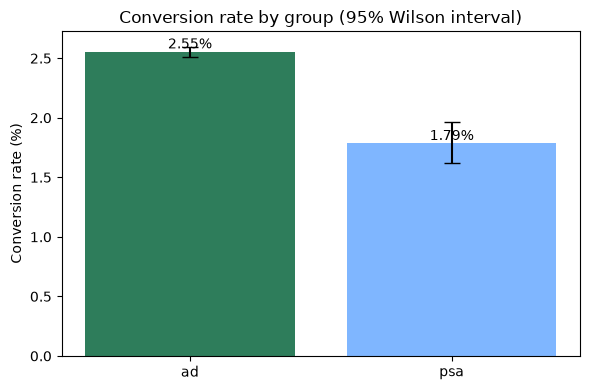

In [30]:
fig, ax = plt.subplots(figsize=(6, 4))
labels = ["ad", "psa"]
rates = [g.loc[k, "rate"] * 100 for k in labels]
err_low = [(g.loc[k, "rate"] - g.loc[k, "ci_low"]) * 100 for k in labels]
err_high = [(g.loc[k, "ci_high"] - g.loc[k, "rate"]) * 100 for k in labels]
ax.bar(labels, rates, yerr=[err_low, err_high], capsize=6, color=["#2e7d5b", "#7fb6ff"])
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Conversion rate by group (95% Wilson interval)")
for i, v in enumerate(rates):
    ax.text(i, v, f"{v:.2f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 5. Was the experiment large enough?
Power analysis at 80% power and a 5% significance level, using the group sizes of this dataset. The control group (`psa`) is the smaller one, so it limits the sensitivity of the test.

In [31]:
analysis = NormalIndPower()
ratio = n_ad / n_psa   # nobs2 / nobs1, with nobs1 = control (psa)

mde_h = analysis.solve_power(effect_size=None, nobs1=n_psa, alpha=ALPHA, power=0.8, ratio=ratio, alternative="two-sided")
phi_psa = 2 * math.asin(math.sqrt(p_psa))
p_ad_mde = math.sin((phi_psa + mde_h) / 2) ** 2   # rate in `ad` that corresponds to Cohen's h = mde_h
print(f"Smallest effect detectable with 80% power: {100 * (p_ad_mde - p_psa):.2f} pp "
      f"(from {p_psa:.2%} to {p_ad_mde:.2%}, relative lift {p_ad_mde / p_psa - 1:.0%})")
print(f"Observed difference: {100 * diff:.2f} pp")

if diff > 0:
    n_needed = analysis.solve_power(effect_size=cohen_h, nobs1=None, alpha=ALPHA, power=0.8, ratio=ratio, alternative="two-sided")
    print(f"To detect the observed difference with 80% power at this group ratio: about {n_needed:,.0f} users in psa "
          f"and {n_needed * ratio:,.0f} in ad (actual: {n_psa:,} and {n_ad:,}).")

Smallest effect detectable with 80% power: 0.26 pp (from 1.79% to 2.04%, relative lift 14%)
Observed difference: 0.77 pp
To detect the observed difference with 80% power at this group ratio: about 2,910 users in psa and 69,848 in ad (actual: 23,524 and 564,577).


## 6. Exploratory: day and hour of most exposure
**Treat these as hypotheses, not findings.** Many segments are tested at once, so some will look significant by chance. The Holm correction below controls for that. Segments with fewer than 30 users in either group are skipped.

In [32]:
def segment_tests(data, by):
    rows = []
    for key, s in data.groupby(by):
        a = s.loc[s["test_group"] == "ad", "converted"]
        c = s.loc[s["test_group"] == "psa", "converted"]
        n1, n2, x1, x2 = len(a), len(c), int(a.sum()), int(c.sum())
        row = {by: key, "n_ad": n1, "n_psa": n2, "rate_ad": a.mean() if n1 else np.nan, "rate_psa": c.mean() if n2 else np.nan}
        if n1 < 30 or n2 < 30 or (x1 + x2) == 0 or (x1 + x2) == (n1 + n2):
            row.update({"diff_pp": np.nan, "ci_low_pp": np.nan, "ci_high_pp": np.nan, "p_value": np.nan})
        else:
            _, p = proportions_ztest([x1, x2], [n1, n2])
            lo, hi = confint_proportions_2indep(x1, n1, x2, n2, compare="diff", alpha=ALPHA)
            row.update({"diff_pp": 100 * (x1 / n1 - x2 / n2), "ci_low_pp": 100 * lo, "ci_high_pp": 100 * hi, "p_value": p})
        rows.append(row)
    out = pd.DataFrame(rows)
    ok = out["p_value"].notna()
    out["p_holm"] = np.nan
    if ok.any():
        out.loc[ok, "p_holm"] = multipletests(out.loc[ok, "p_value"], alpha=ALPHA, method="holm")[1]
    out["significant_after_holm"] = out["p_holm"] < ALPHA
    return out

by_day = segment_tests(df, "most_ads_day")
by_day["most_ads_day"] = pd.Categorical(by_day["most_ads_day"], categories=DAYS, ordered=True)
by_day = by_day.sort_values("most_ads_day").reset_index(drop=True)
display(by_day.round(4))

,most_ads_day,n_ad,n_psa,rate_ad,rate_psa,diff_pp,ci_low_pp,ci_high_pp,p_value,p_holm,significant_after_holm
0,Monday,83571,3502,0.0332,0.0226,1.0683,0.5088,1.5272,0.0005,0.0025,True
1,Tuesday,74572,2907,0.0304,0.0144,1.5992,1.0826,1.9939,0.0000,0.0000,True
2,Wednesday,77418,3490,0.0254,0.0158,0.9597,0.4777,1.3400,0.0004,0.0023,True
3,Thursday,79077,3905,0.0216,0.0202,0.1407,-0.3603,0.5507,0.5548,0.5548,False
4,Friday,88805,3803,0.0225,0.0163,0.6162,0.1522,0.9863,0.0116,0.0347,True
5,Saturday,78802,2858,0.0213,0.0140,0.7311,0.2209,1.1153,0.0075,0.0299,True
6,Sunday,82332,3059,0.0246,0.0206,0.4025,-0.1736,0.8618,0.1572,0.3144,False


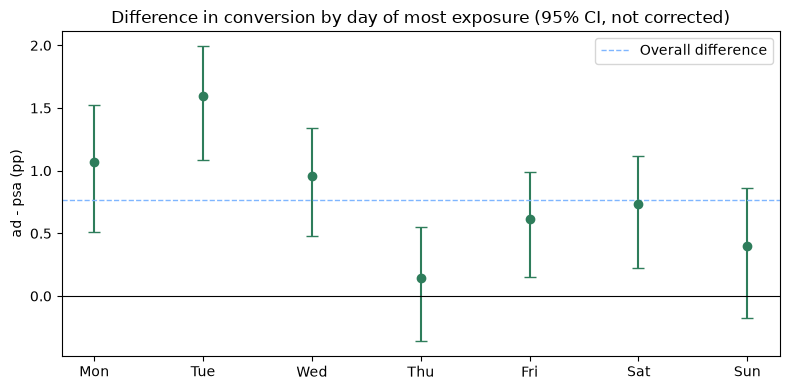

In [33]:
d = by_day.dropna(subset=["diff_pp"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(range(len(d)), d["diff_pp"], yerr=[d["diff_pp"] - d["ci_low_pp"], d["ci_high_pp"] - d["diff_pp"]],
            fmt="o", color="#2e7d5b", capsize=4)
ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(100 * diff, color="#7fb6ff", linestyle="--", linewidth=1, label="Overall difference")
ax.set_xticks(range(len(d)))
ax.set_xticklabels([str(x)[:3] for x in d["most_ads_day"]])
ax.set_ylabel("ad - psa (pp)")
ax.set_title("Difference in conversion by day of most exposure (95% CI, not corrected)")
ax.legend()
plt.tight_layout()
plt.show()

In [34]:
by_hour = segment_tests(df, "most_ads_hour")
display(by_hour.round(4))
print(f"Hours significant after Holm correction: {int(by_hour['significant_after_holm'].sum())} of {int(by_hour['p_value'].notna().sum())} tested")

,most_ads_hour,n_ad,n_psa,rate_ad,rate_psa,diff_pp,ci_low_pp,ci_high_pp,p_value,p_holm,significant_after_holm
0,0,5309,227,0.0192,0.0000,1.9213,0.2236,2.3268,0.0350,0.5607,False
1,1,4615,187,0.0134,0.0000,1.3434,-0.6908,1.7184,0.1106,1.0000,False
2,2,5152,181,0.0076,0.0000,0.7570,-1.3311,1.0331,0.2401,1.0000,False
3,3,2590,89,0.0104,0.0112,-0.0811,-5.0614,0.9564,0.9410,1.0000,False
4,4,694,28,0.0159,0.0000,NaN,NaN,NaN,NaN,NaN,False
5,5,742,23,0.0216,0.0000,NaN,NaN,NaN,NaN,NaN,False
6,6,1985,83,0.0232,0.0000,2.3174,-2.1434,3.0771,0.1607,1.0000,False
7,7,6168,237,0.0185,0.0084,1.0044,-1.1974,1.7183,0.2552,1.0000,False
8,8,16968,659,0.0199,0.0106,0.9239,-0.2078,1.5136,0.0925,1.0000,False
9,9,29802,1202,0.0195,0.0108,0.8714,0.0964,1.3486,0.0309,0.5260,False


Hours significant after Holm correction: 1 of 22 tested


## 7. Exposure (`total_ads`): descriptive only
`total_ads` is measured **after** a user enters the experiment, so it can be affected by the treatment. Comparing conversion across exposure levels does **not** show the effect of seeing more ads; it only describes the data.

In [35]:
exp = df.copy()
exp["exposure_bucket"] = pd.qcut(exp["total_ads"], 5, duplicates="drop")
by_exposure = (exp.groupby(["exposure_bucket", "test_group"], observed=True)["converted"]
                  .agg(users="count", conversion_rate="mean").unstack("test_group"))
display(by_exposure.round(4))

users       conversion_rate        
test_group           ad   psa              ad     psa
exposure_bucket                                      
(0.999, 3.0]     119537  5557          0.0021  0.0018
(3.0, 8.0]       106476  4794          0.0038  0.0054
(8.0, 17.0]      117250  3984          0.0073  0.0073
(17.0, 33.0]     109099  4530          0.0172  0.0163
(33.0, 2065.0]   112215  4659          0.0983  0.0603

## 8. Export for Excel
Three small files in `data/processed/`: the by-group summary, the table by group, day and hour (for the PivotTable), and the Python results to reconcile with the Excel formulas.

In [36]:
os.makedirs(OUT_DIR, exist_ok=True)

by_group = g.reset_index()[["test_group", "users", "conversions"]]
by_group.to_csv(os.path.join(OUT_DIR, "ab_summary_by_group.csv"), index=False)

day_num = {d: i + 1 for i, d in enumerate(DAYS)}
cells = (df.groupby(["test_group", "most_ads_day", "most_ads_hour"])["converted"]
           .agg(users="count", conversions="sum").reset_index())
cells["day_num"] = cells["most_ads_day"].map(day_num)
cells = cells[["test_group", "day_num", "most_ads_day", "most_ads_hour", "users", "conversions"]].sort_values(
    ["test_group", "day_num", "most_ads_hour"])
cells.to_csv(os.path.join(OUT_DIR, "ab_by_group_day_hour.csv"), index=False)

results.to_csv(os.path.join(OUT_DIR, "ab_results_python.csv"), index=False)

print(f"ab_summary_by_group.csv: {len(by_group)} rows | ab_by_group_day_hour.csv: {len(cells):,} rows | ab_results_python.csv: {len(results)} rows")
assert cells["users"].sum() == len(df) and cells["conversions"].sum() == df["converted"].sum(), "Exported totals do not match the data"
print("Exported totals match the cleaned data.")

ab_summary_by_group.csv: 2 rows | ab_by_group_day_hour.csv: 335 rows | ab_results_python.csv: 21 rows
Exported totals match the cleaned data.


## 9. Conclusion

**Result.** Users shown the ad converted at 2.55% (14,423 of 564,577) versus 1.79% (420 of 23,524) for the PSA group: a difference of **+0.77 percentage points** (95% CI: 0.59 to 0.94 pp), a **relative lift of +43%** (95% CI: +30% to +57%). The two-proportion z-test rejects equal conversion rates (z = 7.37, p < 0.001). The effect size is small in standardized terms (Cohen's h = 0.053) but meaningful for a conversion metric.

**Is it conclusive?** Yes, for the overall effect. At 80% power the smallest detectable effect is 0.26 pp (14% relative), about one third of the observed difference, and about 2,900 control users would have sufficed against the 23,524 available.

**Segments (exploratory).** The difference is positive on every weekday and significant after Holm correction on five of seven (Mon, Tue, Wed, Fri, Sat; largest on Tuesday, +1.60 pp). Thursday and Sunday are not significant, but each has only about 3,000 control users, so the intervals are wide; this is not evidence of no effect. By hour, the difference is positive in 21 of 22 hours tested and significant after correction in only one (14:00, +1.25 pp), which is consistent with chance given 29 segment tests. I treat these breakdowns as hypotheses for a follow-up experiment, not as targeting rules.

**Recommendation.** The ad outperforms the PSA on conversion, and the evidence is strong enough to prefer it. Before acting on revenue, the cost of showing ads should be weighed against the incremental conversions (about 0.77 per 100 users).

**Caveats.** The 96/4 split is highly unbalanced, the planned allocation and the data origin are undocumented, and randomization cannot be verified, so a causal reading depends on users having been assigned at random. Only conversion is measured: there is no revenue, cost or long-term effect.

## 10. Limitations
- **Undocumented origin.** The dataset's author does not say whether it is real or simulated, so the results are a methodological exercise.
- **Unknown planned split.** Without it, assignment problems (sample-ratio mismatch) cannot be ruled out.
- **Strong imbalance** between groups (about 96% `ad` / 4% `psa`). The test is still well powered overall (section 5), but segment-level results rest on small control samples.
- **One outcome only** (conversion). Revenue, cost of the ads and long-term effects are not measured.
- **Segments are exploratory** and `total_ads` is a post-treatment variable.
- **Association vs. causation:** randomization is what would allow a causal reading, and it cannot be verified here.
- **Sparse segments.** Overnight hours have few control users and no conversions, so their estimates are unstable; segments with fewer than 30 users in either group are skipped.
- **Multiple comparisons.** Holm correction is applied separately to the day (7) and hour (22) families, not across all 29 tests, and the segment analysis was not pre-specified.